# The Fourier-domain TODCOR method — derived in the open

This tutorial derives the two-component (double-lined) velocity estimator in
`todcor` **from scratch** and verifies every claim numerically — the
"no black box" companion to [`todcor_method.md`](../../packages/todcor/docs/todcor_method.md).
The *applied* fits live in `02_single_window_fit` and `03_multiwindow_combination`.

We use **synthetic templates** so the notebook is self-contained (no external
data). The engine treats any template the same way. Everything below is a live
check: shift theorem, the six sufficient statistics, the closed-form amplitude
fit, profile vs marginal likelihood, the Parseval identity, and the Nyquist drop.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# The TODCOR engine, its forward model, and the shared grid/FFT/broadening
# primitives (re-exported from unicor.dsp) all live in one namespace.
import todcor as tf

# Figure style for the SPARTA examples (LaTeX rendering off for portability).
PAPER_STYLE = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11.0, "axes.titlesize": 11.0, "axes.labelsize": 11.0,
    "xtick.labelsize": 10.0, "ytick.labelsize": 10.0, "legend.fontsize": 8.0,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.direction": "in", "ytick.direction": "in",
    "lines.linewidth": 1.2,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.grid": False,
}
plt.rcParams.update(PAPER_STYLE)

C = tf.C_KMS  # speed of light, km/s

def gauss_line(wave, center, depth, fwhm_kms, emission=False):
    "A single Gaussian absorption (or emission) line on a wavelength grid."
    sigma = (fwhm_kms / 2.3548) * center / C
    prof = depth * np.exp(-0.5 * ((wave - center) / sigma) ** 2)
    return 1.0 + prof if emission else 1.0 - prof

# Uniform log-lambda grid (constant velocity step dv).
lam_lo, lam_hi, dv = 4600.0, 4720.0, 3.0
wave, u = tf.log_lambda_grid(lam_lo, lam_hi, dv)

# Two components: an OB-like absorber (primary) + a WR-like broad emitter (secondary).
tmpl1 = (wave, gauss_line(wave, 4634., 0.25, 120.) * gauss_line(wave, 4686., 0.15, 120.))
tmpl2 = (wave, gauss_line(wave, 4686., 0.60, 400., emission=True))

R = 8000.0  # instrumental resolving power
def prep(tmpl):
    "Resample to the grid, subtract continuum, instrumentally broaden, apodise."
    g = tf.resample(tmpl[0], tmpl[1], wave) - 1.0
    return tf.broaden_gaussian_residual(g, dv, C / R) * tf.tukey_window(len(g))
g1, g2 = prep(tmpl1), prep(tmpl2)
print(f"grid: N={len(wave)} pixels, dv={dv} km/s, R={R:.0f}")

grid: N=2574 pixels, dv=3.0 km/s, R=8000


## 1. A Doppler shift is a phase factor

On a log-λ grid a velocity shift `s_i = c·ln(1 + v_i/c)` (km/s) is a pure
*translation*, so in the Fourier domain it is a phase factor `exp(−2πiζ s)` (the
shift theorem). That is the whole reason the templates can be transformed **once**
and reused at every trial velocity. Check it: shift a template by physical
resampling vs by the Fourier phase, and confirm they agree in the interior.

max |physical - Fourier| in the interior = 7.331953069122932e-07


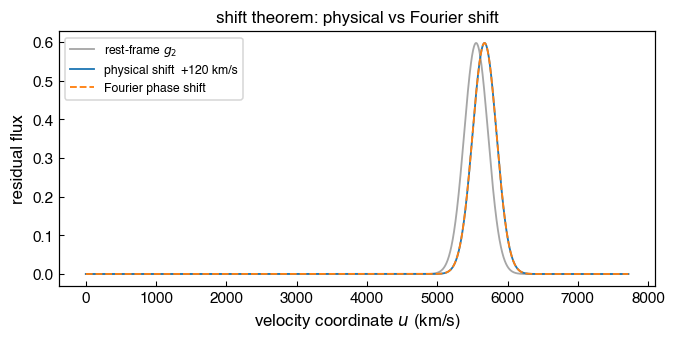

In [2]:
v_test = 120.0
phys = tf.broaden_gaussian_residual(tf.shift_template_flux(tmpl2[0], tmpl2[1], wave, v_test) - 1.0, dv, C / R)
zeta = np.fft.rfftfreq(len(g2), d=dv)
four = np.fft.irfft(np.fft.rfft(g2) * np.exp(-2j * np.pi * zeta * tf.shift_kms(v_test)), n=len(g2))

fig, ax = plt.subplots(figsize=(7, 3.0))
ax.plot(u, g2, color="0.65", label="rest-frame $g_2$")
ax.plot(u, phys, "C0", label=f"physical shift  +{v_test:.0f} km/s")
ax.plot(u, four, "C1--", label="Fourier phase shift")
ax.set_xlabel("velocity coordinate $u$ (km/s)"); ax.set_ylabel("residual flux")
ax.set_title("shift theorem: physical vs Fourier shift"); ax.legend(fontsize=8)
interior = slice(20, -20)
print("max |physical - Fourier| in the interior =", np.max(np.abs((phys - four)[interior])))

## 2. The six sufficient statistics

For one window the weighted χ² at **any** `(v1, v2, a1, a2)` is a fixed quadratic
form in just six numbers (`window_stats`), with per-mode Parseval weight `w_k` and
shifts `s_i`:

$$S_{11}=\sum_k w_k|G_{1k}|^2,\quad S_{22}=\sum_k w_k|G_{2k}|^2,\quad S_D=\sum_k w_k|D_k|^2$$
$$b_1(v_1)=\mathrm{Re}\sum_k w_k\,\overline{G_{1k}}\,D_k\,e^{+2\pi i\zeta_k s_1},\quad
  b_2(v_2)=\mathrm{Re}\sum_k w_k\,\overline{G_{2k}}\,D_k\,e^{+2\pi i\zeta_k s_2}$$
$$A_{12}(v_1,v_2)=\mathrm{Re}\sum_k w_k\,\overline{G_{1k}}\,G_{2k}\,e^{-2\pi i\zeta_k(s_2-s_1)}$$

Expanding $\sum_k w_k|D_k-a_1G_{1k}e^{-i\phi_1}-a_2G_{2k}e^{-i\phi_2}|^2$ gives

$$\chi^2 = S_D - 2(a_1 b_1 + a_2 b_2) + a_1^2 S_{11} + 2 a_1 a_2 A_{12} + a_2^2 S_{22}.$$

**Sufficiency** = given these six, the raw spectrum is never needed again. Verify
by reconstructing χ² at an arbitrary node two ways:

In [3]:
# a noisy composite to play the role of "data"
v1t, v2t, a1t, a2t = 80.0, -160.0, 0.7, 0.55
comp = tf.broaden_gaussian_residual(
    tf.composite_flux(wave, [tmpl1, tmpl2], [v1t, v2t], [a1t, a2t]) - 1.0, dv, C / R) + 1.0
rng = np.random.default_rng(0); sigma = 0.01
data_g = (comp + rng.normal(0, sigma, len(comp)) - 1.0) * tf.tukey_window(len(comp))

v1g = np.arange(-300, 301, 4.0)
v2g = np.arange(-400, 401, 4.0)
st = tf.window_stats(data_g, g1, g2, dv, v1g, v2g, sigma=sigma)
print("shapes:  S11,S22,SD scalars;  b1", st["b1"].shape, " b2", st["b2"].shape, " A12", st["A12"].shape)

i, j, a1, a2 = 30, 40, 0.6, 0.5
chi2_six = (st["SD"] - 2*(a1*st["b1"][i] + a2*st["b2"][j])
            + a1**2*st["S11"] + 2*a1*a2*st["A12"][i, j] + a2**2*st["S22"])
# direct: rebuild the Fourier model at the same node and form the weighted residual chi^2
D, zeta = tf.rfft_positive(data_g, dv)
G1 = np.fft.rfft(g1)[1:]; G2 = np.fft.rfft(g2)[1:]
w = tf.parseval_weights(len(data_g), sigma=sigma)
if len(data_g) % 2 == 0:
    D, G1, G2, zeta, w = D[:-1], G1[:-1], G2[:-1], zeta[:-1], w[:-1]
M = (a1*G1*np.exp(-2j*np.pi*zeta*tf.shift_kms(v1g[i]))
     + a2*G2*np.exp(-2j*np.pi*zeta*tf.shift_kms(v2g[j])))
chi2_direct = np.sum(w * np.abs(D - M)**2)
print(f"chi^2 from 6 statistics = {chi2_six:.6f}")
print(f"chi^2 from raw spectrum = {chi2_direct:.6f}")
print(f"relative difference     = {abs(chi2_six-chi2_direct)/chi2_direct:.1e}   <- sufficiency")

shapes:  S11,S22,SD scalars;  b1 (151,)  b2 (201,)  A12 (151, 201)
chi^2 from 6 statistics = 31892.731623
chi^2 from raw spectrum = 31892.731623
relative difference     = 0.0e+00   <- sufficiency


## 3. Profiling the amplitudes (2×2 weighted least squares)

χ² is quadratic in `(a1, a2)`, so at each `(v1, v2)` the best amplitudes solve the
2×2 normal equations `N a = b`, `N = [[S11, A12], [A12, S22]]`:

$$\det = S_{11}S_{22}-A_{12}^2,\qquad
  a_1 = \frac{S_{22}b_1-A_{12}b_2}{\det},\qquad
  a_2 = \frac{S_{11}b_2-A_{12}b_1}{\det}.$$

Verify the closed form against `np.linalg.solve` and a brute-force grid search:

In [4]:
S11, S22, A12 = st["S11"], st["S22"], st["A12"][i, j]
b1v, b2v = st["b1"][i], st["b2"][j]
det = S11*S22 - A12**2
a_closed = np.array([(S22*b1v - A12*b2v)/det, (S11*b2v - A12*b1v)/det])
a_solve = np.linalg.solve([[S11, A12], [A12, S22]], [b1v, b2v])

ag = np.linspace(-0.5, 1.2, 601)
A1, A2 = np.meshgrid(ag, ag, indexing="ij")
chi2 = st["SD"] - 2*(A1*b1v + A2*b2v) + A1**2*S11 + 2*A1*A2*A12 + A2**2*S22
p, q = np.unravel_index(np.argmin(chi2), chi2.shape)
print(f"closed form : a = ({a_closed[0]:+.4f}, {a_closed[1]:+.4f})")
print(f"np.solve    : a = ({a_solve[0]:+.4f}, {a_solve[1]:+.4f})")
print(f"brute force : a = ({ag[p]:+.4f}, {ag[q]:+.4f})")
print("\nThis node is off the true velocity, and unconstrained least squares happily")
print("returns a NEGATIVE light fraction a1. That is why the applied fit offers")
print("nonneg=True (a >= 0), demonstrated in notebook 03.")

closed form : a = (-0.1348, +0.5017)
np.solve    : a = (-0.1348, +0.5017)
brute force : a = (-0.1345, +0.5030)

This node is off the true velocity, and unconstrained least squares happily
returns a NEGATIVE light fraction a1. That is why the applied fit offers
nonneg=True (a >= 0), demonstrated in notebook 03.


## 4. Profile vs marginal likelihood

`logL_profile = −χ²/2`. Marginalising the amplitudes under a flat prior on
`(a1, a2) ∈ ℝ²` is a Gaussian integral with precision `N`, adding exactly
`−½ ln|det|` (the amplitude-posterior width). Confirm the two maps differ by that
term, and look at the profile map:

max |(logL_marg - logL_prof) - (-1/2 ln det)| = 3.637978807091713e-12
peak: {'v1': 80.0, 'v2': -160.0, 'a1': 0.7027668422937052, 'a2': 0.5495939751432147, 'chi2': 2408.7031686243863, 'chi2_red': 0.9379685236076273}


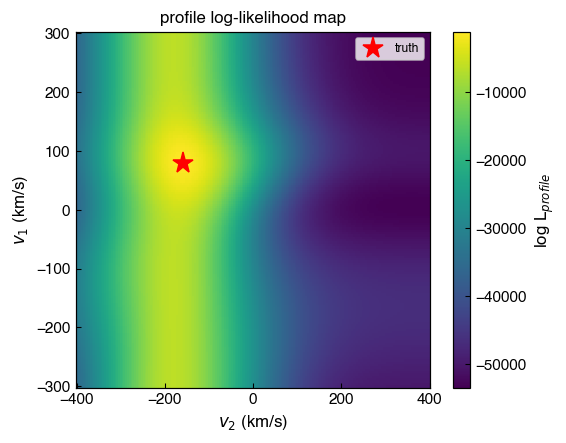

In [5]:
res = tf.profile_from_stats(st, v1g, v2g)
det_map = np.maximum(st["S11"]*st["S22"] - st["A12"]**2, 1e-30)
diff = res["logL_marginal"] - res["logL_profile"]
print("max |(logL_marg - logL_prof) - (-1/2 ln det)| =",
      np.max(np.abs(diff - (-0.5*np.log(det_map)))))

fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.pcolormesh(v2g, v1g, res["logL_profile"], shading="auto", cmap="viridis")
ax.plot(v2t, v1t, "r*", ms=14, label="truth")
ax.set_xlabel("$v_2$ (km/s)"); ax.set_ylabel("$v_1$ (km/s)")
ax.set_title("profile log-likelihood map"); ax.legend(fontsize=8)
fig.colorbar(im, ax=ax, label="log L$_{profile}$")
print("peak:", res["best"])

## 5. Parseval weights — the Fourier χ² *is* the real-space χ²

The per-mode weights (`parseval_weights`) are chosen so
`Σ_k w_k |r_k|² = Σ_n r_n²/σ²`. Dropping the DC bin removes the mean, so the
identity holds for the **mean-subtracted** residual:

In [6]:
r = rng.normal(0, sigma, 257) * tf.tukey_window(257)
Rr = np.fft.rfft(r); wr = tf.parseval_weights(len(r), sigma=sigma)
fourier_chi2 = np.sum(wr * np.abs(Rr[1:])**2)
realspace_chi2 = np.sum((r - r.mean())**2) / sigma**2
print(f"Fourier chi^2 (positive modes) = {fourier_chi2:.6f}")
print(f"real-space chi^2 (mean-subtr.) = {realspace_chi2:.6f}")
print(f"relative difference            = {abs(fourier_chi2-realspace_chi2)/realspace_chi2:.1e}")

Fourier chi^2 (positive modes) = 210.900329
real-space chi^2 (mean-subtr.) = 210.900329
relative difference            = 1.3e-16


## 6. The even-N Nyquist mode is dropped

For even `N` the Nyquist coefficient of a real signal must be real, but the complex
shift factor `exp(−2πiζs)` would make it complex — inconsistent with the
`irfft`-based model. `window_stats` drops that single mode. The payoff: a
*noiseless* composite built with the same Fourier phase-shift model recovers
χ² ≈ 0 at the truth node for **both** even and odd N:

In [7]:
def exact_shift_chi2(n):
    ww = wave[:n]
    gg1 = tf.broaden_gaussian_residual(tf.resample(tmpl1[0], tmpl1[1], ww) - 1., dv, C/R) * tf.tukey_window(n)
    gg2 = tf.broaden_gaussian_residual(tf.resample(tmpl2[0], tmpl2[1], ww) - 1., dv, C/R) * tf.tukey_window(n)
    d = tf.model_flux(ww, dv, gg1, gg2, v1t, v2t, a1t, a2t) - 1.0   # exact Fourier composite
    s = tf.window_stats(d, gg1, gg2, dv, np.array([v1t]), np.array([v2t]), sigma=sigma)
    return tf.profile_from_stats(s, np.array([v1t]), np.array([v2t]))["best"]["chi2"]

for n in (256, 257):
    print(f"N={n} ({'even' if n%2==0 else 'odd '}): exact-shift chi^2 at truth = {exact_shift_chi2(n):.2e}")

N=256 (even): exact-shift chi^2 at truth = 0.00e+00
N=257 (odd ): exact-shift chi^2 at truth = 0.00e+00


## Summary

Everything the estimator does is now explicit: **six sufficient statistics** →
a fixed **quadratic χ²** → a **closed-form 2×2 amplitude fit** → the
**profile/marginal** log-likelihood maps, with a **Parseval-exact** Fourier χ² and
a **Nyquist-consistent** even-N treatment.

- **`02_single_window_fit`** — use `todcor_map` on a realistic single window: read
  the peak, overlay the best-fit spectrum, and validate the CRLB errors against a
  Monte Carlo.
- **`03_multiwindow_combination`** — pool several line windows of one epoch with
  `combine_stats` (the sufficient-statistic *addition*), and see the joint fit
  break a single-window degeneracy.

Full written spec: [`todcor_method.md`](../../packages/todcor/docs/todcor_method.md).